# MPPI Agent — Experiment Notebook

**Mục đích:** Chạy nhiều lần thử nghiệm MPPI với các cấu hình khác nhau

## Cấu trúc notebook
| Cell | Nội dung |
|------|----------|
| 1 | Setup và imports |
| 2 | **CẤU HÌNH THÍ NGHIỆM** |
| 3 | Tạo file config JSON cho mỗi thí nghiệm |
| 4 | Chạy từng thí nghiệm qua CLI |
| 5 | Load kết quả từ `runs/` |
| 6–10 | Vẽ biểu đồ |
| 11 | Bảng tổng hợp so sánh agent |

---
## Cell 1 — Setup

In [6]:
import json
import csv
import subprocess
import sys
import time
import pathlib
import shutil
from dataclasses import dataclass, field
from typing import List, Optional, Dict, Any

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec

matplotlib.rcParams.update({
    'figure.dpi': 130,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'font.family': 'DejaVu Sans',
})

# Đường dẫn gốc của project
PROJECT_ROOT = pathlib.Path("__file__").resolve().parent.parent
# Nếu chạy từ notebooks/, ROOT = thư mục cha
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
# Fallback: tìm bằng marker file
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = pathlib.Path.cwd()
    while PROJECT_ROOT != PROJECT_ROOT.parent:
        if (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT / "runs").exists():
            break
        PROJECT_ROOT = PROJECT_ROOT.parent

RUNS_DIR        = PROJECT_ROOT / "runs"
CONFIGS_DIR     = PROJECT_ROOT / "configs" / "experiments"
RESULTS_DIR     = PROJECT_ROOT / "results" / "mppi_analysis"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"PROJECT_ROOT : {PROJECT_ROOT}")
print(f"RUNS_DIR     : {RUNS_DIR}")
print(f"RESULTS_DIR  : {RESULTS_DIR}")
print(f"Python       : {sys.executable}")

PROJECT_ROOT : /home/nii/Documents/[code]sgu-2026-team-advanced-ai-subject/autonomous-driving-rl
RUNS_DIR     : /home/nii/Documents/[code]sgu-2026-team-advanced-ai-subject/autonomous-driving-rl/runs
RESULTS_DIR  : /home/nii/Documents/[code]sgu-2026-team-advanced-ai-subject/autonomous-driving-rl/results/mppi_analysis
Python       : /home/nii/anaconda3/envs/conda_sgu_2026_ai_advanced/bin/python


---
## Cell 2 — CẤU HÌNH THÍ NGHIỆM

Mỗi `ExperimentSpec` là một lần chạy: 1 config MPPI × 1 scenario.

**Thứ tự nên làm:**
1. Bắt đầu với `Easy/SCS` để chắc pipeline chạy được
2. Tăng lên `Medium/SCXCS`, rồi `Hard/SCXOCS`
3. Thêm sweep horizon, sweep K sau khi đã có baseline

In [7]:
@dataclass
class ExperimentSpec:
    """Một thí nghiệm = 1 bộ config MPPI + 1 scenario MetaDrive."""
    # --- Tên hiển thị trong biểu đồ ---
    label: str

    # --- Scenario (map) ---
    tier: str        # "Easy", "Medium", "Hard", "Extreme"
    sequence: str    # chuỗi block ("SCS", "SCXCS", "SCXOCS", ...)
    geom_seed: int   # seed hình học (0, 1, 2, ...)
    env_seed: int    # seed xe (0, 1, 2, ...)

    # --- Tham số MPPI (các key phải khớp với MPPIConfig) ---
    mppi_params: Dict[str, Any] = field(default_factory=dict)

    # --- Custom run id để dễ nhận diện ---
    custom_run_id: Optional[str] = None

    # --- Tên file config JSON tạm ---
    @property
    def config_filename(self) -> str:
        safe = self.label.replace(" ", "_").replace("/", "-").replace("=", "")
        return f"notebook_mppi_{safe}.json"


# ---- THAM SỐ MPPI GỐC (baseline) ----
BASE_MPPI_PARAMS = {
    "horizon": 20,
    "num_samples": 512,
    "temperature": 0.5,
    "sigma_steering": 0.3,
    "sigma_throttle": 0.5,
    "noise_correlation": 0.8,
    "integration_dt_s": 0.02,
    "max_speed_kmh": 80.0,
    "target_speed_m_s": 16.0,
    "wheelbase_m": 2.46894,
    "max_steering_deg": 40.0,
    "steering_sign": 1.0,
    "acceleration_m_s2": 4.0,
    "braking_m_s2": 8.0,
    "drag_per_s": 0.05,
    "vehicle_length_m": 4.515,
    "vehicle_width_m": 1.852,
    "lane_margin_m": 0.1,
    "obstacle_margin_m": 0.5,
    "lidar_range_m": 50.0,
    "lateral_accel_max_m_s2": 3.0,
    "lateral_weight": 2.0,
    "heading_weight": 1.0,
    "speed_weight": 0.5,
    "steering_weight": 0.1,
    "control_change_weight": 1.0,
    "progress_weight": 1.0,
    "outside_penalty": 50.0,
    "collision_penalty": 500.0,
}

def make_params(**overrides) -> Dict[str, Any]:
    """Tạo dict tham số từ BASE, ghi đè các key trong overrides."""
    p = BASE_MPPI_PARAMS.copy()
    p.update(overrides)
    return p


# DANH SÁCH THÍ NGHIỆM 
EXPERIMENTS: List[ExperimentSpec] = [

    # --- NHÓM 1: Baseline H=20 trên 3 mức độ khó ---
    ExperimentSpec(
        label="H20 Easy",
        tier="Easy", sequence="SCS", geom_seed=0, env_seed=0,
        mppi_params=make_params(horizon=20),
        custom_run_id="nb_mppi_H20_easy_g0_e0",
    ),
    ExperimentSpec(
        label="H20 Medium",
        tier="Medium", sequence="SCXCS", geom_seed=0, env_seed=0,
        mppi_params=make_params(horizon=20),
        custom_run_id="nb_mppi_H20_medium_g0_e0",
    ),
    ExperimentSpec(
        label="H20 Hard",
        tier="Hard", sequence="SCXOCS", geom_seed=0, env_seed=0,
        mppi_params=make_params(horizon=20),
        custom_run_id="nb_mppi_H20_hard_g0_e0",
    ),

    # --- NHÓM 2: Sweep Horizon (giữ nguyên scenario Medium) ---
    ExperimentSpec(
        label="H10 Medium",
        tier="Medium", sequence="SCXCS", geom_seed=0, env_seed=0,
        mppi_params=make_params(horizon=10),
        custom_run_id="nb_mppi_H10_medium_g0_e0",
    ),
    ExperimentSpec(
        label="H30 Medium",
        tier="Medium", sequence="SCXCS", geom_seed=0, env_seed=0,
        mppi_params=make_params(horizon=30),
        custom_run_id="nb_mppi_H30_medium_g0_e0",
    ),

    # --- NHÓM 3: Sweep Temperature λ (giữ nguyên scenario Medium, H=20) ---
    ExperimentSpec(
        label="λ=0.1 Medium",
        tier="Medium", sequence="SCXCS", geom_seed=0, env_seed=0,
        mppi_params=make_params(horizon=20, temperature=0.1),
        custom_run_id="nb_mppi_lam01_medium_g0_e0",
    ),
    ExperimentSpec(
        label="λ=1.0 Medium",
        tier="Medium", sequence="SCXCS", geom_seed=0, env_seed=0,
        mppi_params=make_params(horizon=20, temperature=1.0),
        custom_run_id="nb_mppi_lam10_medium_g0_e0",
    ),

    # --- NHÓM 4: Sweep K (num_samples) ---
    ExperimentSpec(
        label="K=128 Medium",
        tier="Medium", sequence="SCXCS", geom_seed=0, env_seed=0,
        mppi_params=make_params(horizon=20, num_samples=128),
        custom_run_id="nb_mppi_K128_medium_g0_e0",
    ),
    ExperimentSpec(
        label="K=1024 Medium",
        tier="Medium", sequence="SCXCS", geom_seed=0, env_seed=0,
        mppi_params=make_params(horizon=20, num_samples=1024),
        custom_run_id="nb_mppi_K1024_medium_g0_e0",
    ),
]

print(f"Tổng số thí nghiệm sẽ chạy: {len(EXPERIMENTS)}")
for i, exp in enumerate(EXPERIMENTS):
    print(f"  [{i+1:02d}] {exp.label:<20} | {exp.tier}/{exp.sequence} geom={exp.geom_seed} env={exp.env_seed} | H={exp.mppi_params['horizon']} K={exp.mppi_params['num_samples']} λ={exp.mppi_params['temperature']}")

Tổng số thí nghiệm sẽ chạy: 9
  [01] H20 Easy             | Easy/SCS geom=0 env=0 | H=20 K=512 λ=0.5
  [02] H20 Medium           | Medium/SCXCS geom=0 env=0 | H=20 K=512 λ=0.5
  [03] H20 Hard             | Hard/SCXOCS geom=0 env=0 | H=20 K=512 λ=0.5
  [04] H10 Medium           | Medium/SCXCS geom=0 env=0 | H=10 K=512 λ=0.5
  [05] H30 Medium           | Medium/SCXCS geom=0 env=0 | H=30 K=512 λ=0.5
  [06] λ=0.1 Medium         | Medium/SCXCS geom=0 env=0 | H=20 K=512 λ=0.1
  [07] λ=1.0 Medium         | Medium/SCXCS geom=0 env=0 | H=20 K=512 λ=1.0
  [08] K=128 Medium         | Medium/SCXCS geom=0 env=0 | H=20 K=128 λ=0.5
  [09] K=1024 Medium        | Medium/SCXCS geom=0 env=0 | H=20 K=1024 λ=0.5


---
## Cell 3 — Tạo file config JSON cho mỗi thí nghiệm

In [8]:
NOTEBOOK_CONFIGS_DIR = CONFIGS_DIR / "notebook_runs"
NOTEBOOK_CONFIGS_DIR.mkdir(parents=True, exist_ok=True)

def write_mppi_config(exp: ExperimentSpec) -> pathlib.Path:
    """Ghi file JSON config MPPI cho một thí nghiệm. Trả về đường dẫn file."""
    # Xác định version dựa vào horizon
    h = exp.mppi_params.get("horizon", 20)
    version = "mppi_planner_v2" if h > 20 else "mppi_planner_v1"

    payload = {
        "version": version,
        "parameters": exp.mppi_params,
    }
    path = NOTEBOOK_CONFIGS_DIR / exp.config_filename
    path.write_text(json.dumps(payload, indent=2), encoding="utf-8")
    return path


config_paths = {}
for exp in EXPERIMENTS:
    p = write_mppi_config(exp)
    config_paths[exp.label] = p
    print(f"  Wrote: {p.relative_to(PROJECT_ROOT)}")

print(f"\nTổng: {len(config_paths)} file config đã ghi vào {NOTEBOOK_CONFIGS_DIR.relative_to(PROJECT_ROOT)}")

  Wrote: configs/experiments/notebook_runs/notebook_mppi_H20_Easy.json
  Wrote: configs/experiments/notebook_runs/notebook_mppi_H20_Medium.json
  Wrote: configs/experiments/notebook_runs/notebook_mppi_H20_Hard.json
  Wrote: configs/experiments/notebook_runs/notebook_mppi_H10_Medium.json
  Wrote: configs/experiments/notebook_runs/notebook_mppi_H30_Medium.json
  Wrote: configs/experiments/notebook_runs/notebook_mppi_λ0.1_Medium.json
  Wrote: configs/experiments/notebook_runs/notebook_mppi_λ1.0_Medium.json
  Wrote: configs/experiments/notebook_runs/notebook_mppi_K128_Medium.json
  Wrote: configs/experiments/notebook_runs/notebook_mppi_K1024_Medium.json

Tổng: 9 file config đã ghi vào configs/experiments/notebook_runs


---
## Cell 4 — Chạy từng thí nghiệm qua CLI

> **Lưu ý:** Mỗi lần chạy sẽ khởi động MetaDrive simulator.  
> Với 8 thí nghiệm × ~1 phút mỗi thí nghiệm ≈ **~8 phút**.  
> Nếu `custom_run_id` đã tồn tại trong `runs/`, nó sẽ tự động bỏ qua (skip).

In [9]:
# ---- Hàm kiểm tra run đã tồn tại chưa ----
def run_exists(custom_run_id: Optional[str]) -> Optional[pathlib.Path]:
    """Trả về đường dẫn run_dir nếu đã tồn tại và hoàn chỉnh, None nếu chưa."""
    if custom_run_id is None:
        return None
    candidate = RUNS_DIR / custom_run_id
    if candidate.exists() and (candidate / "summary.json").exists():
        return candidate
    return None


# ---- Hàm sửa CONFIG_PATH trong MPPI.py trỏ đến config mới ----
# Thay vì sửa source code, ta dùng env variable để inject config
# Nhưng project không support env var, nên ta patch file trực tiếp (chỉ trong notebook)
def patch_mppi_config_path(new_config_path: pathlib.Path):
    """Thay đổi CONFIG_PATH trong MPPI.py để trỏ đến config mới."""
    mppi_py = PROJECT_ROOT / "src" / "agents" / "MPPI.py"
    text = mppi_py.read_text(encoding="utf-8")
    # Tìm dòng CONFIG_PATH = ...
    lines = text.split("\n")
    new_lines = []
    for line in lines:
        if line.strip().startswith("CONFIG_PATH") and "Path(__file__)" in line:
            # Thay bằng đường dẫn tuyệt đối
            new_lines.append(f'CONFIG_PATH = pathlib.Path(r"{new_config_path.as_posix()}")')
        else:
            new_lines.append(line)
    mppi_py.write_text("\n".join(new_lines), encoding="utf-8")


def restore_mppi_config_path():
    """Khôi phục CONFIG_PATH về dạng gốc dùng __file__."""
    mppi_py = PROJECT_ROOT / "src" / "agents" / "MPPI.py"
    text = mppi_py.read_text(encoding="utf-8")
    lines = text.split("\n")
    new_lines = []
    for line in lines:
        if line.strip().startswith("CONFIG_PATH") and "pathlib.Path(r\"" in line:
            # Khôi phục về dạng gốc
            new_lines.append(
                'CONFIG_PATH = (\n'
                '    Path(__file__).resolve().parents[2]\n'
                '    / "configs/experiments/mppi_v2_h30.json"\n'
                ')'
            )
        else:
            new_lines.append(line)
    mppi_py.write_text("\n".join(new_lines), encoding="utf-8")


# ---- Hàm chạy 1 thí nghiệm ----
def run_experiment(exp: ExperimentSpec, skip_existing: bool = True) -> Optional[pathlib.Path]:
    """
    Chạy 1 thí nghiệm qua CLI và trả về đường dẫn run_dir.
    skip_existing=True: bỏ qua nếu run đã tồn tại.
    """
    # 1. Kiểm tra đã chạy chưa
    existing = run_exists(exp.custom_run_id)
    if skip_existing and existing:
        print(f"  <->  SKIP (đã tồn tại): {exp.label} → {existing.name}")
        return existing

    # 2. Patch CONFIG_PATH
    config_path = config_paths[exp.label]
    patch_mppi_config_path(config_path)

    # 3. Build CLI command
    cmd = [
        sys.executable, "-m", "src.launcher.cli", "run",
        "--mode", "SANDBOX",
        "--agent", "stage3_mppi",
        "--tier", exp.tier,
        "--sequence", exp.sequence,
        "--geom-seed", str(exp.geom_seed),
        "--env-seed", str(exp.env_seed),
        "--agent-seed", "101",
        "--wandb", "DISABLED",
    ]
    if exp.custom_run_id:
        cmd += ["--run-id", exp.custom_run_id]

    # 4. Chạy
    t0 = time.perf_counter()
    print(f"  -->  RUNNING: {exp.label}")
    print(f"     cmd: {' '.join(cmd[2:])}")
    result = subprocess.run(
        cmd,
        cwd=str(PROJECT_ROOT),
        capture_output=True,
        text=True,
    )
    elapsed = time.perf_counter() - t0

    # 5. Khôi phục CONFIG_PATH
    restore_mppi_config_path()

    # 6. Kiểm tra kết quả
    if result.returncode != 0:
        print(f"  X  FAILED ({elapsed:.1f}s): {exp.label}")
        print(f"     STDERR: {result.stderr[-500:]}")
        return None

    # 7. Tìm run_dir vừa tạo
    run_dir = run_exists(exp.custom_run_id)
    if run_dir is None:
        # Tìm run mới nhất nếu không có custom_run_id
        all_runs = sorted(RUNS_DIR.iterdir(), key=lambda p: p.stat().st_mtime, reverse=True)
        run_dir = next((r for r in all_runs if (r / "summary.json").exists()), None)

    if run_dir:
        summary = json.loads((run_dir / "summary.json").read_text())
        m = summary.get("overall_metrics", {})
        print(f"  X  DONE  ({elapsed:.1f}s): {exp.label} → RC={m.get('mean_final_route_completion',0):.3f} crash={m.get('crash_vehicle_rate',0):.2f} success={m.get('clean_success_rate',0):.2f}")
    return run_dir

In [10]:
# CHẠY TẤT CẢ THÍ NGHIỆM
# Nếu muốn chạy lại từ đầu: đặt skip_existing=False
SKIP_EXISTING = True  # <-- True: bỏ qua run đã có; False: chạy lại tất cả

run_dirs: Dict[str, Optional[pathlib.Path]] = {}  # label -> run_dir

print(f"{'='*60}")
print(f"Bắt đầu {len(EXPERIMENTS)} thí nghiệm (skip_existing={SKIP_EXISTING})")
print(f"{'='*60}")

for i, exp in enumerate(EXPERIMENTS, 1):
    print(f"\n[{i}/{len(EXPERIMENTS)}] {exp.label}")
    run_dir = run_experiment(exp, skip_existing=SKIP_EXISTING)
    run_dirs[exp.label] = run_dir

print(f"\n{'='*60}")
print("Hoàn thành tất cả thí nghiệm.")
success_count = sum(1 for v in run_dirs.values() if v is not None)
print(f"Thành công: {success_count}/{len(EXPERIMENTS)}")

Bắt đầu 9 thí nghiệm (skip_existing=True)

[1/9] H20 Easy
  <->  SKIP (đã tồn tại): H20 Easy → nb_mppi_H20_easy_g0_e0

[2/9] H20 Medium
  -->  RUNNING: H20 Medium
     cmd: src.launcher.cli run --mode SANDBOX --agent stage3_mppi --tier Medium --sequence SCXCS --geom-seed 0 --env-seed 0 --agent-seed 101 --wandb DISABLED --run-id nb_mppi_H20_medium_g0_e0
  X  FAILED (1.4s): H20 Medium
     STDERR: [ERROR] Execution failed: Duplicate run error: run directory '/home/nii/Documents/[code]sgu-2026-team-advanced-ai-subject/autonomous-driving-rl/runs/nb_mppi_H20_medium_g0_e0' already exists! Overwriting or appending to existing scientific runs is strictly forbidden.


[3/9] H20 Hard
  -->  RUNNING: H20 Hard
     cmd: src.launcher.cli run --mode SANDBOX --agent stage3_mppi --tier Hard --sequence SCXOCS --geom-seed 0 --env-seed 0 --agent-seed 101 --wandb DISABLED --run-id nb_mppi_H20_hard_g0_e0
  X  DONE  (55.9s): H20 Hard → RC=0.748 crash=1.00 success=0.00

[4/9] H10 Medium
  -->  RUNNING: H10 M

---
## Cell 5 — Load kết quả từ `runs/`

In [11]:
def load_run_data(run_dir: pathlib.Path, label: str, exp: ExperimentSpec) -> Optional[Dict]:
    """Load summary + episodes.csv + timing.csv từ một run_dir."""
    if run_dir is None or not run_dir.exists():
        return None
    try:
        summary  = json.loads((run_dir / "summary.json").read_text())
        episodes = pd.read_csv(run_dir / "episodes.csv")
        timing   = pd.read_csv(run_dir / "timing.csv")
    except FileNotFoundError as e:
        print(f"  WARN: {label} thiếu file — {e}")
        return None

    om = summary.get("overall_metrics", {})
    return {
        "label": label,
        "run_id": summary.get("run_id", run_dir.name),
        "run_dir": run_dir,
        "exp": exp,
        # Tham số chính để nhóm
        "horizon": exp.mppi_params.get("horizon", "?"),
        "num_samples": exp.mppi_params.get("num_samples", "?"),
        "temperature": exp.mppi_params.get("temperature", "?"),
        "tier": exp.tier,
        "sequence": exp.sequence,
        # Metric tổng hợp
        "rc_mean": om.get("mean_final_route_completion", np.nan),
        "rc_median": om.get("median_final_route_completion", np.nan),
        "crash_vehicle": om.get("crash_vehicle_rate", np.nan),
        "out_of_road": om.get("out_of_road_rate", np.nan),
        "success_rate": om.get("clean_success_rate", np.nan),
        "mean_speed": om.get("mean_speed_kmh", np.nan),
        "mean_return": om.get("mean_episode_return", np.nan),
        "total_episodes": om.get("total_episodes", 0),
        # Timing
        "mean_act_ms": timing["mean_act_ms"].mean() if len(timing) else np.nan,
        "max_act_ms": timing["max_act_ms"].max() if len(timing) else np.nan,
        # DataFrames đầy đủ để vẽ per-episode
        "episodes_df": episodes,
        "timing_df": timing,
    }


# Load tất cả run
results: List[Dict] = []
for exp in EXPERIMENTS:
    rd = run_dirs.get(exp.label)
    data = load_run_data(rd, exp.label, exp)
    if data:
        results.append(data)
        print(f"  OK {exp.label:<22} RC={data['rc_mean']:.3f} crash={data['crash_vehicle']:.2f} success={data['success_rate']:.2f} speed={data['mean_speed']:.1f}km/h act={data['mean_act_ms']:.1f}ms")
    else:
        print(f"  XXX {exp.label:<22} (không có dữ liệu)")

print(f"\nLoaded: {len(results)}/{len(EXPERIMENTS)} thí nghiệm")

# Tạo DataFrame tổng hợp để dễ filter
summary_df = pd.DataFrame([
    {k: v for k, v in r.items() if k not in ("episodes_df", "timing_df", "run_dir", "exp")}
    for r in results
])
summary_df

  OK H20 Easy               RC=0.988 crash=0.00 success=1.00 speed=27.3km/h act=41.7ms
  XXX H20 Medium             (không có dữ liệu)
  OK H20 Hard               RC=0.748 crash=1.00 success=0.00 speed=18.8km/h act=44.1ms
  OK H10 Medium             RC=0.991 crash=0.00 success=1.00 speed=27.4km/h act=41.8ms
  OK H30 Medium             RC=0.991 crash=0.00 success=1.00 speed=27.4km/h act=42.5ms
  OK λ=0.1 Medium           RC=0.991 crash=0.00 success=1.00 speed=27.4km/h act=41.9ms
  OK λ=1.0 Medium           RC=0.991 crash=0.00 success=1.00 speed=27.4km/h act=42.5ms
  OK K=128 Medium           RC=0.991 crash=0.00 success=1.00 speed=27.4km/h act=41.8ms
  OK K=1024 Medium          RC=0.991 crash=0.00 success=1.00 speed=27.4km/h act=41.5ms

Loaded: 8/9 thí nghiệm


,label,run_id,horizon,num_samples,temperature,tier,sequence,rc_mean,rc_median,crash_vehicle,out_of_road,success_rate,mean_speed,mean_return,total_episodes,mean_act_ms,max_act_ms
0,H20 Easy,nb_mppi_H20_easy_g0_e0,20,512,0.5,Easy,SCS,0.987768,0.987768,0.0,0.0,1.0,27.292507,1.880537,1,41.707724,83.647645
1,H20 Hard,nb_mppi_H20_hard_g0_e0,20,512,0.5,Hard,SCXOCS,0.747834,0.747834,1.0,0.0,0.0,18.771953,-0.372865,1,44.079416,104.206272
2,H10 Medium,nb_mppi_H10_medium_g0_e0,10,512,0.5,Medium,SCXCS,0.991176,0.991176,0.0,0.0,1.0,27.429832,1.883780,1,41.799611,83.763009
3,H30 Medium,nb_mppi_H30_medium_g0_e0,30,512,0.5,Medium,SCXCS,0.991176,0.991176,0.0,0.0,1.0,27.429832,1.883780,1,42.523124,82.292075
4,λ=0.1 Medium,nb_mppi_lam01_medium_g0_e0,20,512,0.1,Medium,SCXCS,0.991176,0.991176,0.0,0.0,1.0,27.429832,1.883780,1,41.896930,71.891921
5,λ=1.0 Medium,nb_mppi_lam10_medium_g0_e0,20,512,1.0,Medium,SCXCS,0.991176,0.991176,0.0,0.0,1.0,27.429832,1.883780,1,42.452447,61.186698
6,K=128 Medium,nb_mppi_K128_medium_g0_e0,20,128,0.5,Medium,SCXCS,0.991176,0.991176,0.0,0.0,1.0,27.429832,1.883780,1,41.806240,56.725934
7,K=1024 Medium,nb_mppi_K1024_medium_g0_e0,20,1024,0.5,Medium,SCXCS,0.991176,0.991176,0.0,0.0,1.0,27.429832,1.883780,1,41.466509,96.068518


---
## Cell 6 — Plot 1: Route Completion theo Tier (độ khó)

Saved: /home/nii/Documents/[code]sgu-2026-team-advanced-ai-subject/autonomous-driving-rl/results/mppi_analysis/plot1_rc_by_tier.png


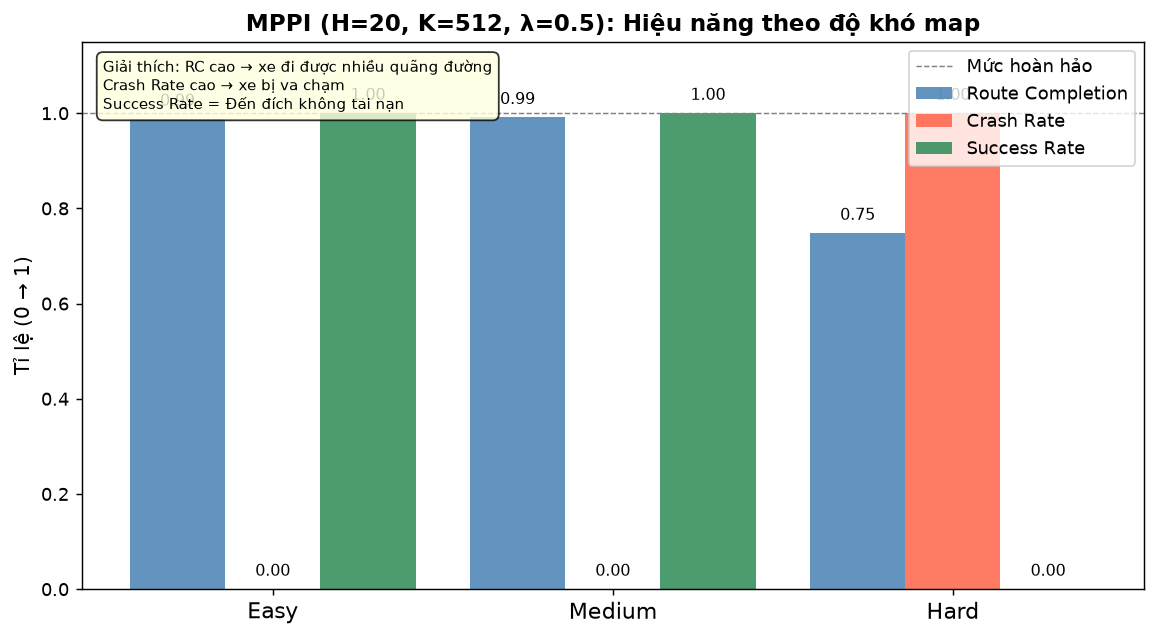

In [12]:
def plot_rc_by_tier(results: List[Dict], save_path: Optional[pathlib.Path] = None):
    """
    Vẽ bar chart: Route Completion của MPPI H=20 trên 3 mức độ khó.
    Giúp trả lời: 'MPPI hoạt động tốt ở độ khó nào?'
    """
    # Lọc chỉ lấy H=20
    h20 = [r for r in results if r["horizon"] == 20]
    if not h20:
        print("Không có dữ liệu H=20 để vẽ.")
        return

    tier_order = ["Easy", "Medium", "Hard", "Extreme"]
    by_tier = {r["tier"]: r for r in h20}
    tiers = [t for t in tier_order if t in by_tier]

    rc_vals    = [by_tier[t]["rc_mean"] for t in tiers]
    crash_vals = [by_tier[t]["crash_vehicle"] for t in tiers]
    success_vals = [by_tier[t]["success_rate"] for t in tiers]

    x = np.arange(len(tiers))
    width = 0.28

    fig, ax = plt.subplots(figsize=(9, 5))
    bars_rc = ax.bar(x - width, rc_vals, width, label="Route Completion", color="steelblue", alpha=0.85)
    bars_cr = ax.bar(x,          crash_vals, width, label="Crash Rate",      color="tomato",    alpha=0.85)
    bars_sc = ax.bar(x + width,  success_vals, width, label="Success Rate",  color="seagreen",  alpha=0.85)

    ax.set_xticks(x)
    ax.set_xticklabels(tiers, fontsize=12)
    ax.set_ylabel("Tỉ lệ (0 → 1)")
    ax.set_title("MPPI (H=20, K=512, λ=0.5): Hiệu năng theo độ khó map", fontweight="bold")
    ax.set_ylim(0, 1.15)
    ax.axhline(1.0, color="gray", ls="--", lw=0.8, label="Mức hoàn hảo")
    ax.legend(loc="upper right")

    for bar in bars_rc + bars_cr + bars_sc:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.02, f"{h:.2f}",
                ha="center", va="bottom", fontsize=9)

    ax.text(0.02, 0.97,
        "Giải thích: RC cao → xe đi được nhiều quãng đường\n"
        "Crash Rate cao → xe bị va chạm\n"
        "Success Rate = Đến đích không tai nạn",
        transform=ax.transAxes, fontsize=8.5,
        va="top", bbox=dict(boxstyle="round,pad=0.4", facecolor="lightyellow", alpha=0.8)
    )

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Saved: {save_path}")
    plt.show()


plot_rc_by_tier(results, save_path=RESULTS_DIR / "plot1_rc_by_tier.png")

---
## Cell 7 — Plot 2: Sweep Horizon H (ablation study)

Saved: /home/nii/Documents/[code]sgu-2026-team-advanced-ai-subject/autonomous-driving-rl/results/mppi_analysis/plot2_horizon_sweep.png


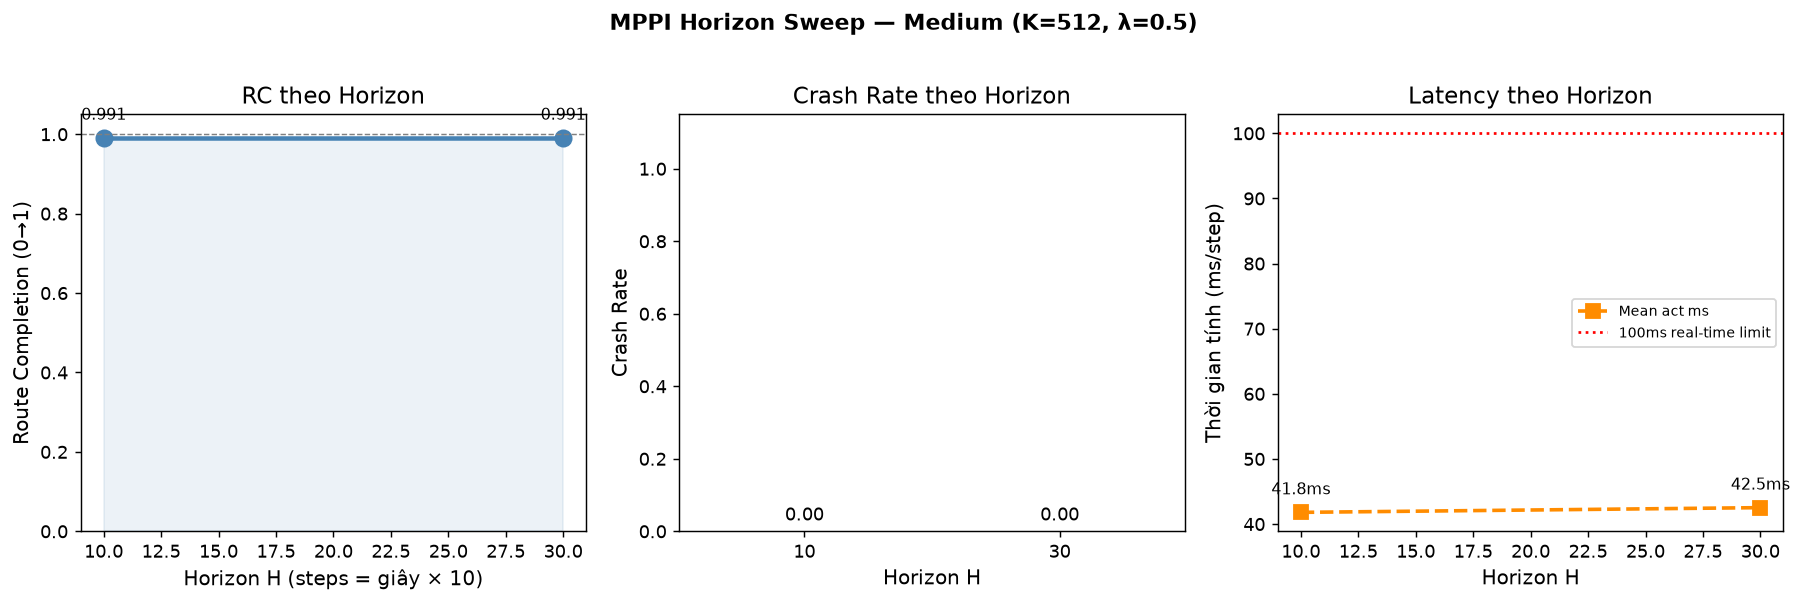

In [13]:
def plot_horizon_sweep(results: List[Dict], tier_filter: str = "Medium",
                       save_path: Optional[pathlib.Path] = None):
    """
    Vẽ: Route Completion và Timing (ms/step) theo Horizon H.
    Giúp trả lời: 'H bao nhiêu là tốt nhất? Đánh đổi giữa chất lượng và tốc độ?'
    """
    # Lọc theo tier và K=512, λ=0.5
    sweep = [
        r for r in results
        if r["tier"] == tier_filter
        and r["num_samples"] == 512
        and r["temperature"] == 0.5
    ]
    sweep = sorted(sweep, key=lambda r: r["horizon"])

    if len(sweep) < 2:
        print(f"Cần ít nhất 2 điểm cho sweep H (tier={tier_filter}). Hiện có: {len(sweep)}")
        return

    horizons  = [r["horizon"]      for r in sweep]
    rc_vals   = [r["rc_mean"]      for r in sweep]
    act_ms    = [r["mean_act_ms"]  for r in sweep]
    crash_vals = [r["crash_vehicle"] for r in sweep]

    fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

    # --- Subplot 1: Route Completion ---
    ax = axes[0]
    ax.plot(horizons, rc_vals, "o-", color="steelblue", lw=2.5, ms=9, label="RC")
    ax.fill_between(horizons, rc_vals, alpha=0.1, color="steelblue")
    ax.set_xlabel("Horizon H (steps = giây × 10)")
    ax.set_ylabel("Route Completion (0→1)")
    ax.set_title("RC theo Horizon")
    ax.set_ylim(0, 1.05)
    ax.axhline(1.0, color="gray", ls="--", lw=0.8)
    for x_val, y_val in zip(horizons, rc_vals):
        ax.annotate(f"{y_val:.3f}", (x_val, y_val), textcoords="offset points",
                    xytext=(0, 10), ha="center", fontsize=9)

    # --- Subplot 2: Crash Rate ---
    ax = axes[1]
    ax.bar([str(h) for h in horizons], crash_vals, color="tomato", alpha=0.8)
    ax.set_xlabel("Horizon H")
    ax.set_ylabel("Crash Rate")
    ax.set_title("Crash Rate theo Horizon")
    ax.set_ylim(0, 1.15)
    for i, v in enumerate(crash_vals):
        ax.text(i, v + 0.03, f"{v:.2f}", ha="center", fontsize=10)

    # --- Subplot 3: Latency ---
    ax = axes[2]
    ax.plot(horizons, act_ms, "s--", color="darkorange", lw=2, ms=8, label="Mean act ms")
    ax.axhline(100, color="red", ls=":", lw=1.5, label="100ms real-time limit")
    ax.set_xlabel("Horizon H")
    ax.set_ylabel("Thời gian tính (ms/step)")
    ax.set_title("Latency theo Horizon")
    ax.legend(fontsize=8)
    for x_val, y_val in zip(horizons, act_ms):
        ax.annotate(f"{y_val:.1f}ms", (x_val, y_val), textcoords="offset points",
                    xytext=(0, 10), ha="center", fontsize=9)

    fig.suptitle(f"MPPI Horizon Sweep — {tier_filter} (K=512, λ=0.5)", fontweight="bold", y=1.02)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Saved: {save_path}")
    plt.show()


plot_horizon_sweep(results, tier_filter="Medium", save_path=RESULTS_DIR / "plot2_horizon_sweep.png")

---
## Cell 8 — Plot 3: Sweep Temperature λ

Saved: /home/nii/Documents/[code]sgu-2026-team-advanced-ai-subject/autonomous-driving-rl/results/mppi_analysis/plot3_temperature_sweep.png


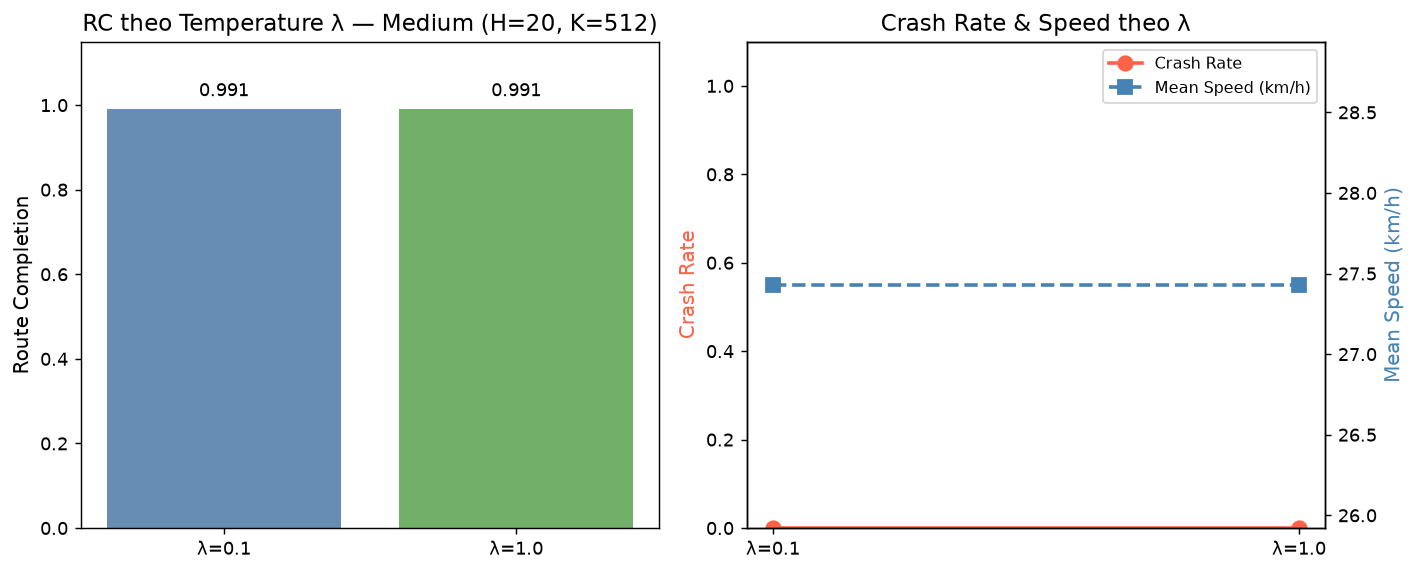

In [14]:
def plot_temperature_sweep(results: List[Dict], tier_filter: str = "Medium",
                            save_path: Optional[pathlib.Path] = None):
    """
    Vẽ: RC và tốc độ theo Temperature λ.
    Giúp trả lời: 'Chọn gắt (λ nhỏ) hay trộn đều (λ lớn) thì tốt hơn?'
    λ nhỏ → tập trung vào mẫu tốt nhất → quyết đoán nhưng có thể miss
    λ lớn → trung bình đều → ổn định nhưng thiếu quyết đoán
    """
    sweep = [
        r for r in results
        if r["tier"] == tier_filter
        and r["horizon"] == 20
        and r["num_samples"] == 512
    ]
    sweep = sorted(sweep, key=lambda r: r["temperature"])

    if len(sweep) < 2:
        print(f"Cần ít nhất 2 điểm cho sweep λ. Hiện có: {len(sweep)}")
        return

    temps  = [r["temperature"] for r in sweep]
    rc_vals = [r["rc_mean"]    for r in sweep]
    speed_vals = [r["mean_speed"] for r in sweep]
    crash_vals = [r["crash_vehicle"] for r in sweep]
    labels = [f"λ={t}" for t in temps]

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

    ax = axes[0]
    bars = ax.bar(labels, rc_vals, color=["#4e79a7", "#59a14f", "#f28e2b", "#e15759"][:len(temps)], alpha=0.85)
    ax.set_ylabel("Route Completion")
    ax.set_title(f"RC theo Temperature λ — {tier_filter} (H=20, K=512)")
    ax.set_ylim(0, 1.15)
    for bar, v in zip(bars, rc_vals):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 0.03, f"{v:.3f}",
                ha="center", fontsize=10)

    ax = axes[1]
    ax.plot(labels, crash_vals, "o-", color="tomato", lw=2, ms=8, label="Crash Rate")
    ax2 = ax.twinx()
    ax2.plot(labels, speed_vals, "s--", color="steelblue", lw=2, ms=8, label="Mean Speed (km/h)")
    ax.set_ylabel("Crash Rate", color="tomato")
    ax2.set_ylabel("Mean Speed (km/h)", color="steelblue")
    ax.set_title("Crash Rate & Speed theo λ")
    ax.set_ylim(0, 1.1)
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, loc="upper right", fontsize=9)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Saved: {save_path}")
    plt.show()


plot_temperature_sweep(results, save_path=RESULTS_DIR / "plot3_temperature_sweep.png")

---
## Cell 9 — Plot 4: Phân phối RC và Speed per episode

Saved: /home/nii/Documents/[code]sgu-2026-team-advanced-ai-subject/autonomous-driving-rl/results/mppi_analysis/plot4_episode_distributions.png


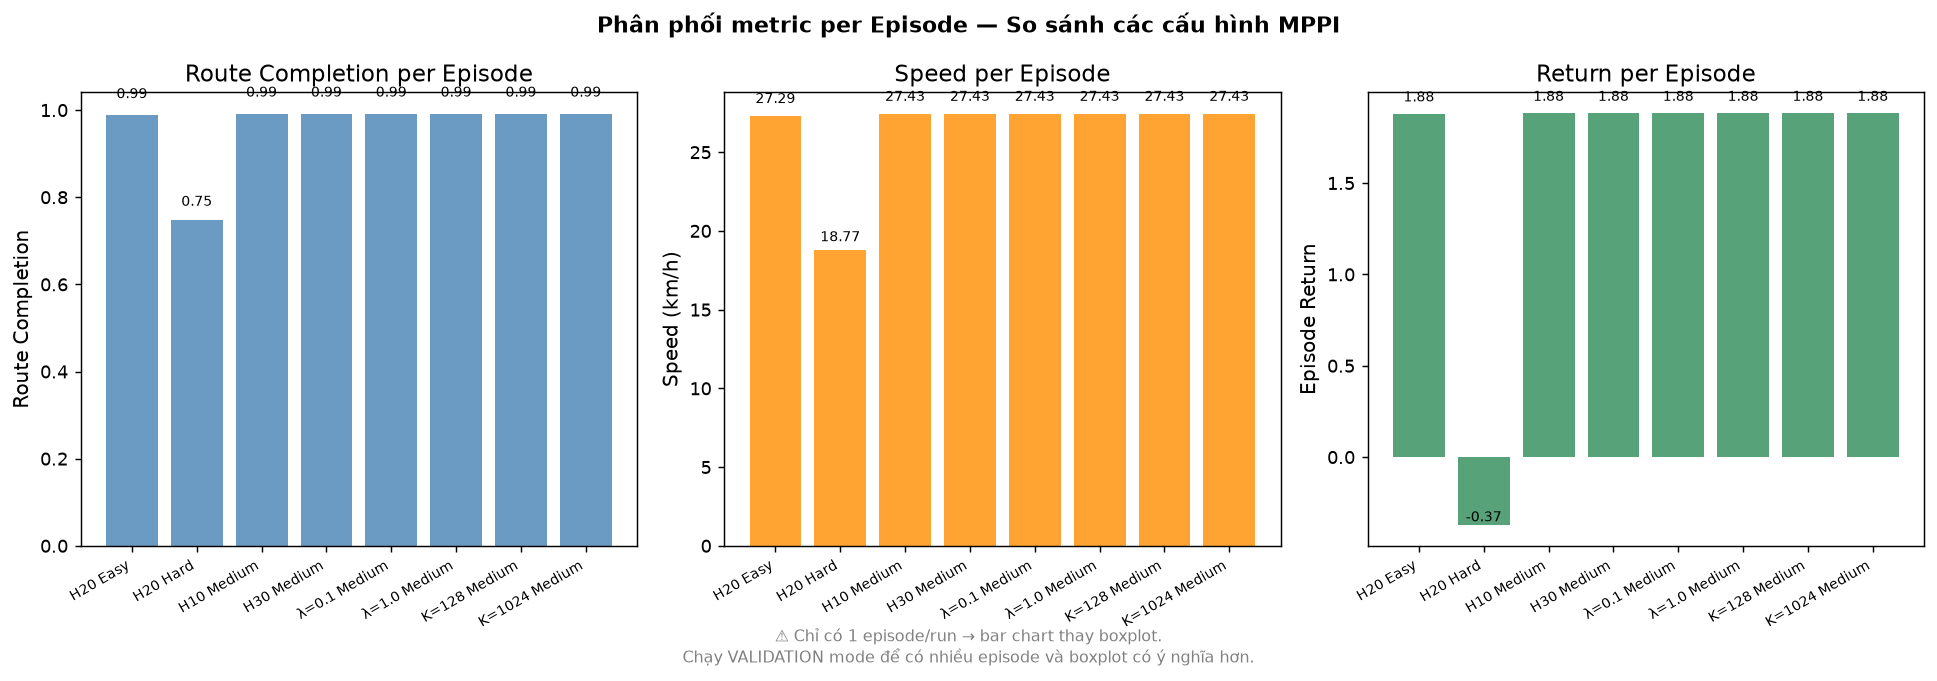

In [15]:
def plot_episode_distributions(results: List[Dict], labels_to_show: Optional[List[str]] = None,
                                save_path: Optional[pathlib.Path] = None):
    """
    Vẽ boxplot/stripplot phân phối RC và Speed của từng thí nghiệm qua các episode.
    Hữu ích khi có nhiều episode (run VALIDATION mode).
    Hiện tại mỗi run chỉ có 1 episode → vẽ bar chart thay.
    """
    if labels_to_show:
        filtered = [r for r in results if r["label"] in labels_to_show]
    else:
        filtered = results

    if not filtered:
        print("Không có dữ liệu.")
        return

    labels = [r["label"] for r in filtered]
    rc_per_ep = [r["episodes_df"]["final_route_completion"].values for r in filtered]
    speed_per_ep = [r["episodes_df"]["mean_speed_kmh"].values for r in filtered]
    return_per_ep = [r["episodes_df"]["episode_return"].values for r in filtered]

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    for ax, data, ylabel, title, color in [
        (axes[0], rc_per_ep,     "Route Completion", "Route Completion per Episode", "steelblue"),
        (axes[1], speed_per_ep,  "Speed (km/h)",     "Speed per Episode",            "darkorange"),
        (axes[2], return_per_ep, "Episode Return",   "Return per Episode",           "seagreen"),
    ]:
        # Nếu chỉ có 1 episode thì vẽ bar; nhiều episode thì vẽ boxplot
        max_len = max(len(d) for d in data)
        if max_len == 1:
            vals = [d[0] if len(d) > 0 else np.nan for d in data]
            bars = ax.bar(range(len(labels)), vals, color=color, alpha=0.8)
            ax.set_xticks(range(len(labels)))
            ax.set_xticklabels(labels, rotation=30, ha="right", fontsize=8)
            for bar, v in zip(bars, vals):
                if np.isfinite(v):
                    ax.text(bar.get_x() + bar.get_width() / 2,
                            v + abs(v) * 0.03 + 0.01,
                            f"{v:.2f}", ha="center", fontsize=8)
        else:
            bp = ax.boxplot(data, labels=labels, patch_artist=True,
                           boxprops=dict(facecolor=color, alpha=0.6),
                           medianprops=dict(color="black", lw=2))
            ax.set_xticklabels(labels, rotation=30, ha="right", fontsize=8)

        ax.set_ylabel(ylabel)
        ax.set_title(title)

    if max_len == 1:
        fig.text(0.5, -0.02,
            "⚠ Chỉ có 1 episode/run → bar chart thay boxplot.\n"
            "Chạy VALIDATION mode để có nhiều episode và boxplot có ý nghĩa hơn.",
            ha="center", fontsize=9, color="gray")

    fig.suptitle("Phân phối metric per Episode — So sánh các cấu hình MPPI", fontweight="bold")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Saved: {save_path}")
    plt.show()


plot_episode_distributions(results, save_path=RESULTS_DIR / "plot4_episode_distributions.png")

---
## Cell 10 — Plot 5: Radar Chart so sánh cấu hình tốt nhất

Saved: /home/nii/Documents/[code]sgu-2026-team-advanced-ai-subject/autonomous-driving-rl/results/mppi_analysis/plot5_radar_comparison.png


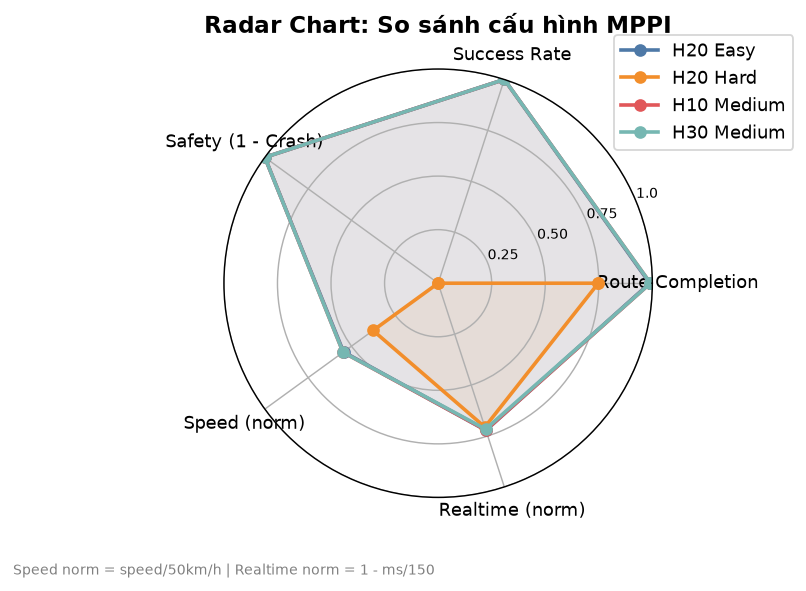

In [16]:
def plot_radar_comparison(results: List[Dict], labels_to_show: Optional[List[str]] = None,
                           save_path: Optional[pathlib.Path] = None):
    """
    Radar chart so sánh các cấu hình MPPI trên 5 tiêu chí.
    Mỗi trục là 1 metric, chuẩn hóa về [0, 1]:
        RC, Success, 1-Crash, Speed/50, 1-Latency/150
    """
    if labels_to_show:
        filtered = [r for r in results if r["label"] in labels_to_show]
    else:
        # Chọn tối đa 5 để không rối
        filtered = results[:5]

    if not filtered:
        print("Không có dữ liệu.")
        return

    metric_names = [
        "Route Completion",
        "Success Rate",
        "Safety (1 - Crash)",
        "Speed (norm)",
        "Realtime (norm)",
    ]
    N = len(metric_names)
    angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
    angles += angles[:1]  # đóng vòng

    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
    colors = ["#4e79a7", "#f28e2b", "#e15759", "#76b7b2", "#59a14f"]

    for r, color in zip(filtered, colors):
        vals = [
            min(r["rc_mean"], 1.0),
            min(r["success_rate"], 1.0),
            max(0.0, 1.0 - r["crash_vehicle"]),
            min(r["mean_speed"] / 50.0, 1.0),   # 50 km/h = chuẩn hóa
            max(0.0, 1.0 - r["mean_act_ms"] / 150.0),  # 150ms = worst
        ]
        vals += vals[:1]
        ax.plot(angles, vals, "o-", lw=2, label=r["label"], color=color)
        ax.fill(angles, vals, alpha=0.08, color=color)

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(metric_names, fontsize=10)
    ax.set_ylim(0, 1)
    ax.set_yticks([0.25, 0.5, 0.75, 1.0])
    ax.set_yticklabels(["0.25", "0.50", "0.75", "1.0"], fontsize=8)
    ax.set_title("Radar Chart: So sánh cấu hình MPPI", fontweight="bold", pad=20)
    ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1))

    ax.text(0, -0.18,
        "Speed norm = speed/50km/h | Realtime norm = 1 - ms/150",
        ha="center", transform=ax.transAxes, fontsize=8, color="gray")

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Saved: {save_path}")
    plt.show()


# Chọn các label muốn so sánh trong radar
plot_radar_comparison(
    results,
    labels_to_show=["H20 Easy", "H20 Medium", "H20 Hard", "H10 Medium", "H30 Medium"],
    save_path=RESULTS_DIR / "plot5_radar_comparison.png",
)

---
## Cell 11 — Plot 6: Timing — phân phối latency act() per step

Saved: /home/nii/Documents/[code]sgu-2026-team-advanced-ai-subject/autonomous-driving-rl/results/mppi_analysis/plot6_timing.png


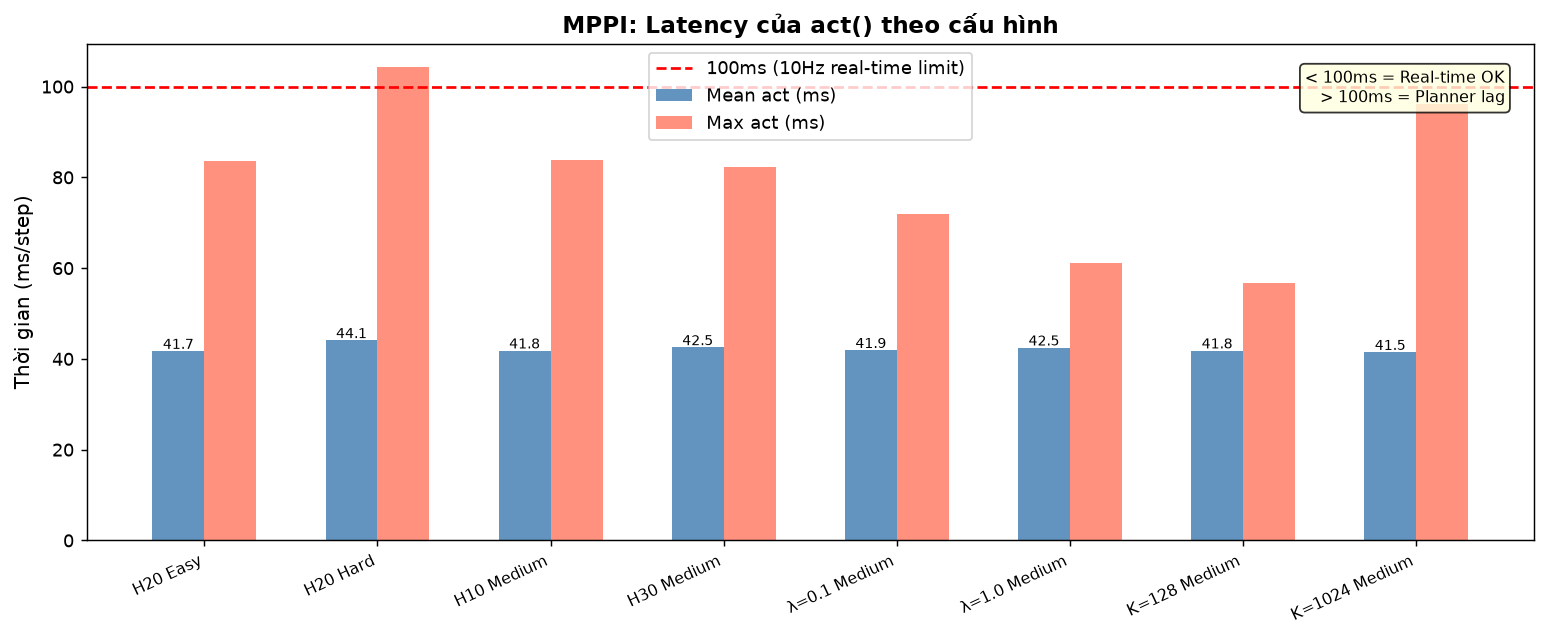

In [17]:
def plot_timing_comparison(results: List[Dict], save_path: Optional[pathlib.Path] = None):
    """
    Vẽ: Mean + P95 latency theo cấu hình.
    Quan trọng: MPPI phải < 100ms/step để chạy real-time (10 Hz).
    """
    df = pd.DataFrame([
        {
            "label": r["label"],
            "mean_ms": r["timing_df"]["mean_act_ms"].mean(),
            "p95_ms": r["timing_df"]["p95_act_ms"].max() if "p95_act_ms" in r["timing_df"].columns else np.nan,
            "max_ms": r["timing_df"]["max_act_ms"].max(),
        }
        for r in results
    ])

    x = np.arange(len(df))
    width = 0.3

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.bar(x - width/2, df["mean_ms"], width, label="Mean act (ms)", color="steelblue", alpha=0.85)
    ax.bar(x + width/2, df["max_ms"],  width, label="Max act (ms)",  color="tomato",   alpha=0.7)

    ax.axhline(100, color="red", ls="--", lw=1.5, label="100ms (10Hz real-time limit)")
    ax.set_xticks(x)
    ax.set_xticklabels(df["label"], rotation=25, ha="right", fontsize=9)
    ax.set_ylabel("Thời gian (ms/step)")
    ax.set_title("MPPI: Latency của act() theo cấu hình", fontweight="bold")
    ax.legend()

    for i, row in df.iterrows():
        ax.text(i - width/2, row["mean_ms"] + 0.5, f"{row['mean_ms']:.1f}",
                ha="center", fontsize=8)

    ax.text(0.98, 0.95,
        "< 100ms = Real-time OK\n> 100ms = Planner lag",
        transform=ax.transAxes, ha="right", va="top", fontsize=9,
        bbox=dict(boxstyle="round", facecolor="lightyellow", alpha=0.8)
    )

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Saved: {save_path}")
    plt.show()


plot_timing_comparison(results, save_path=RESULTS_DIR / "plot6_timing.png")

---
## Cell 12 — Bảng tổng hợp so sánh tất cả agent (cho slide)

In [18]:
def load_other_agent_results(agent_id: str) -> Optional[Dict]:
    """
    Load kết quả của một agent khác (random, rule-based, PPO) từ runs/.
    Lấy run mới nhất có agent_id tương ứng.
    """
    candidates = []
    for run_dir in RUNS_DIR.iterdir():
        if not run_dir.is_dir(): continue
        mf = run_dir / "run_manifest.json"
        sf = run_dir / "summary.json"
        if not (mf.exists() and sf.exists()): continue
        try:
            m = json.loads(mf.read_text())
            if m.get("config", {}).get("agent_id") == agent_id:
                candidates.append((run_dir.stat().st_mtime, run_dir))
        except Exception:
            continue

    if not candidates:
        return None
    _, run_dir = max(candidates)
    summary = json.loads((run_dir / "summary.json").read_text())
    om = summary.get("overall_metrics", {})
    return {
        "rc_mean": om.get("mean_final_route_completion", np.nan),
        "crash_vehicle": om.get("crash_vehicle_rate", np.nan),
        "out_of_road": om.get("out_of_road_rate", np.nan),
        "success_rate": om.get("clean_success_rate", np.nan),
        "mean_speed": om.get("mean_speed_kmh", np.nan),
        "mean_return": om.get("mean_episode_return", np.nan),
        "total_episodes": om.get("total_episodes", 0),
    }


# ---- Thêm các agent khác vào bảng ----
# Điền agent_id thực tế của project (xem src/launcher/registry.py)
OTHER_AGENTS = {
    # "agent_id_trong_registry": "Tên hiển thị"
    "fixture_seeded_random": "Random",
    "stage1_rule_based":    "Rule-based",
    "stage5_sac":           "SAC (RL)",
}

comparison_rows = []

# Thêm agent khác
for agent_id, display_name in OTHER_AGENTS.items():
    data = load_other_agent_results(agent_id)
    if data:
        comparison_rows.append({"Agent": display_name, "Phương pháp": "Khác", **data})
    else:
        comparison_rows.append({"Agent": display_name, "Phương pháp": "Khác",
                                 "rc_mean": "—", "crash_vehicle": "—",
                                 "success_rate": "—", "mean_speed": "—",
                                 "mean_return": "—", "total_episodes": 0})

# Thêm MPPI tốt nhất
for r in results:
    comparison_rows.append({
        "Agent": f"MPPI ({r['label']})",
        "Phương pháp": f"Simulation/H={r['horizon']}/K={r['num_samples']}/λ={r['temperature']}",
        "rc_mean": r["rc_mean"],
        "crash_vehicle": r["crash_vehicle"],
        "out_of_road": r.get("out_of_road", np.nan),
        "success_rate": r["success_rate"],
        "mean_speed": r["mean_speed"],
        "mean_return": r["mean_return"],
        "total_episodes": r["total_episodes"],
    })

# Hiển thị bảng
comp_df = pd.DataFrame(comparison_rows)
comp_df = comp_df.rename(columns={
    "rc_mean": "Route Completion ↑",
    "crash_vehicle": "Crash Rate ↓",
    "out_of_road": "Out-of-Road ↓",
    "success_rate": "Success Rate ↑",
    "mean_speed": "Speed (km/h)",
    "mean_return": "Return",
    "total_episodes": "# Episodes",
})

# Format số
numeric_cols = ["Route Completion ↑", "Crash Rate ↓", "Out-of-Road ↓", "Success Rate ↑", "Speed (km/h)", "Return"]
for col in numeric_cols:
    comp_df[col] = comp_df[col].apply(
        lambda x: f"{x:.3f}" if isinstance(x, float) and np.isfinite(x) else x
    )

print("\n" + "="*80)
print("BẢNG SO SÁNH TỔNG HỢP — Tất cả Agent")
print("="*80)
print(comp_df.to_string(index=False))

# Lưu CSV
comp_df.to_csv(RESULTS_DIR / "comparison_table.csv", index=False)
print(f"\nSaved: {RESULTS_DIR / 'comparison_table.csv'}")


BẢNG SO SÁNH TỔNG HỢP — Tất cả Agent
               Agent                  Phương pháp Route Completion ↑ Crash Rate ↓ Success Rate ↑ Speed (km/h) Return  # Episodes Out-of-Road ↓
              Random                         Khác                  —            —              —            —      —           0           NaN
          Rule-based                         Khác                  —            —              —            —      —           0           NaN
            SAC (RL)                         Khác                  —            —              —            —      —           0           NaN
     MPPI (H20 Easy)  Simulation/H=20/K=512/λ=0.5              0.988        0.000          1.000       27.293  1.881           1         0.000
     MPPI (H20 Hard)  Simulation/H=20/K=512/λ=0.5              0.748        1.000          0.000       18.772 -0.373           1         0.000
   MPPI (H10 Medium)  Simulation/H=10/K=512/λ=0.5              0.991        0.000          1.000       2

---
## Cell 13 — Export tất cả biểu đồ + summary

In [19]:
print("\n" + "="*60)
print("TÓM TẮT THÍ NGHIỆM MPPI")
print("="*60)

if results:
    best = max(results, key=lambda r: r["rc_mean"] if np.isfinite(r["rc_mean"]) else -1)
    print(f"\nConfig tốt nhất (RC cao nhất): '{best['label']}'")
    print(f"  Horizon H  = {best['horizon']}")
    print(f"  Num Samples K = {best['num_samples']}")
    print(f"  Temperature λ = {best['temperature']}")
    print(f"  Route Completion = {best['rc_mean']:.3f}")
    print(f"  Success Rate     = {best['success_rate']:.3f}")
    print(f"  Crash Rate       = {best['crash_vehicle']:.3f}")
    print(f"  Mean Speed       = {best['mean_speed']:.1f} km/h")
    print(f"  Mean act latency = {best['mean_act_ms']:.1f} ms")

print(f"\nFiles đã lưu tại: {RESULTS_DIR}")
for f in sorted(RESULTS_DIR.glob("*")):
    print(f"  {f.name}")

print("\n" + "="*60)
print("Điểm nói trong báo cáo / slide:")
print("  1. MPPI = Rollout/Simulation tương đương MCTS nhưng cho action liên tục")
print("  2. Không cần train; hiệu năng phụ thuộc config H, K, λ và cost weights")
print("  3. Dùng Kinematic Bicycle Model thay vì rollout trong simulator thật")
print("  4. Tradeoff H: nhìn xa hơn → RC tốt hơn, nhưng latency tăng")
print("  5. Nếu act > 100ms → planner lag → cần giảm K hoặc H")
print("="*60)


TÓM TẮT THÍ NGHIỆM MPPI

Config tốt nhất (RC cao nhất): 'H10 Medium'
  Horizon H  = 10
  Num Samples K = 512
  Temperature λ = 0.5
  Route Completion = 0.991
  Success Rate     = 1.000
  Crash Rate       = 0.000
  Mean Speed       = 27.4 km/h
  Mean act latency = 41.8 ms

Files đã lưu tại: /home/nii/Documents/[code]sgu-2026-team-advanced-ai-subject/autonomous-driving-rl/results/mppi_analysis
  comparison_table.csv
  plot1_rc_by_tier.png
  plot2_horizon_sweep.png
  plot3_temperature_sweep.png
  plot4_episode_distributions.png
  plot5_radar_comparison.png
  plot6_timing.png

Điểm nói trong báo cáo / slide:
  1. MPPI = Rollout/Simulation tương đương MCTS nhưng cho action liên tục
  2. Không cần train; hiệu năng phụ thuộc config H, K, λ và cost weights
  3. Dùng Kinematic Bicycle Model thay vì rollout trong simulator thật
  4. Tradeoff H: nhìn xa hơn → RC tốt hơn, nhưng latency tăng
  5. Nếu act > 100ms → planner lag → cần giảm K hoặc H
